In [1]:
import numpy as np 
import torch as tt 
import torch.nn as nn 

Entropy and Cross-entropy 

In [2]:
p = .24 


H = - (p * np.log(p) + (1-p) * np.log(1-p) ) 
#                -> models prediction     1-p -> for binary prediction 
print(H)

0.5510799280869728


Cross entropy 

In [3]:
p = [1,0] # -> real lables 
q = [.5, .5] # -> model prediction 


H = 0 
for i in range(len(p)) : 
    H -= p[i] * np.log(q[i]) 

print(H)

0.6931471805599453


In [4]:
q_tensort = tt.Tensor(q) 
p_tensor = tt.Tensor(p) 

nn.functional.binary_cross_entropy(q_tensort,p_tensor)

tensor(0.6931)

# Variance 

In [5]:
# min & max 

t1 = tt.rand(4,5) 
t1

tensor([[0.3045, 0.3971, 0.4840, 0.5660, 0.8064],
        [0.2347, 0.7353, 0.6973, 0.8043, 0.7649],
        [0.8682, 0.3763, 0.3065, 0.6654, 0.2587],
        [0.6076, 0.5257, 0.0960, 0.5244, 0.4352]])

In [6]:
t1.max(dim=0) # colume 

# dim=1     -> row

torch.return_types.max(
values=tensor([0.8682, 0.7353, 0.6973, 0.8043, 0.8064]),
indices=tensor([2, 1, 1, 1, 0]))

In [7]:
t1[:, 1]

tensor([0.3971, 0.7353, 0.3763, 0.5257])

In [8]:
t1[1:-1, 1:-1]

tensor([[0.7353, 0.6973, 0.8043],
        [0.3763, 0.3065, 0.6654]])

In [9]:
# always rows(0) first and columes(1) second (2,4) except for dim (1,0)

In [10]:
a = tt.Tensor([3,2,2,2,1]) 
b = tt.Tensor([14,4,-5,-5,2])

In [11]:
print(tt.mean(a)) 
print(tt.mean(b))

tensor(2.)
tensor(2.)


In [12]:
print(tt.var(a))

tensor(0.5000)


In [13]:
print(tt.var(b))

tensor(61.5000)


### derivative 

In [14]:
def f(x) : 
    return x ** 3

def df(x) : 
    return 3 * x ** 2  


In [15]:
x = tt.linspace(-1,1,50)
x

tensor([-1.0000, -0.9592, -0.9184, -0.8776, -0.8367, -0.7959, -0.7551, -0.7143,
        -0.6735, -0.6327, -0.5918, -0.5510, -0.5102, -0.4694, -0.4286, -0.3878,
        -0.3469, -0.3061, -0.2653, -0.2245, -0.1837, -0.1429, -0.1020, -0.0612,
        -0.0204,  0.0204,  0.0612,  0.1020,  0.1429,  0.1837,  0.2245,  0.2653,
         0.3061,  0.3469,  0.3878,  0.4286,  0.4694,  0.5102,  0.5510,  0.5918,
         0.6327,  0.6735,  0.7143,  0.7551,  0.7959,  0.8367,  0.8776,  0.9184,
         0.9592,  1.0000])

In [16]:
fx = f(x) 
dx = df(x) 

In [17]:
import matplotlib.pyplot as plt 

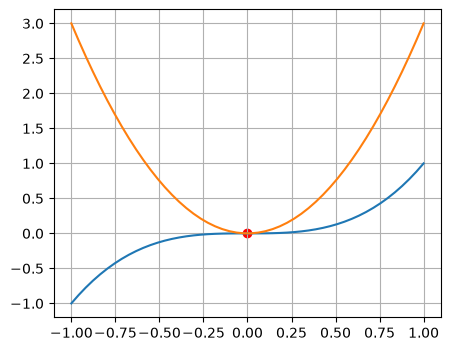

In [18]:
plt.figure(figsize=(5,4))   
plt.plot(x,fx)   
plt.plot(x,dx)   

plt.grid()
plt.scatter(0,0, c='red')
plt.show()   

In [19]:
# minima :    ->    df < 0 (left) &  df > 0 (right) 

# maxima :    ->    df > 0 (left) & df < 0 (right) 

# df = 0 


Gradiant decend 

In [20]:
localmin = np.random.choice(x, 1) 
localmin 

array([-0.06122451], dtype=float32)

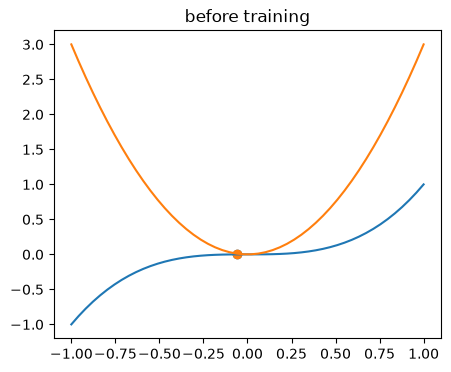

In [21]:
plt.figure(figsize=(5,4)) 
plt.plot(x, fx) 
plt.plot(x, dx) 

plt.title("before training")
plt.scatter(localmin, f(localmin))
plt.scatter(localmin, df(localmin))


In [22]:
lr = .01 

training_epoch = 100 

for i in range(training_epoch) : 
    grad = df(localmin) 
    localmin = localmin - lr * grad 

print(localmin) 
print(f"learning rate : {lr}") 
print(f"number of training : {training_epoch}")

[-0.0749659]
learning rate : 0.01
number of training : 100


In [23]:
type(localmin)

numpy.ndarray

Text(0.5, 1.0, 'after training')

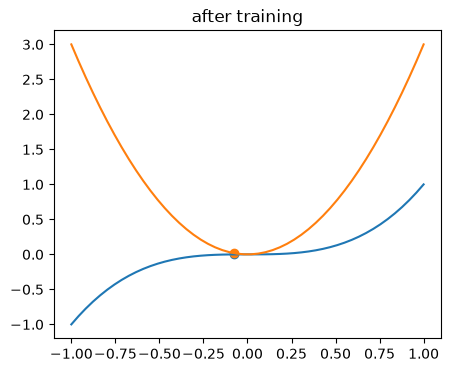

In [24]:
plt.figure(figsize=(5,4)) 
plt.plot(x, fx) 
plt.plot(x, dx) 

plt.scatter(localmin, f(localmin))
plt.scatter(localmin, df(localmin))
plt.title("after training")

### Track localmin at random starting points 

In [25]:
def f(x) : 
    return np.sin(x) + 0.3 * np.sin(3*x) + 0.1 * x 

def df(x) : 
    return np.cos(x) + .9 * np.cos(3*x) + .1 

In [26]:
x = np.linspace(-10,10,1000)

In [27]:
fx = f(x) 
dx = df(x) 

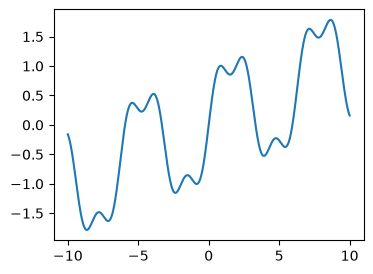

In [28]:
plt.figure(figsize=(4,3)) 
plt.plot(x, fx)
plt.show() 

In [29]:
localmin = np.random.choice(x, 1) 
localmin

array([-9.7997998])

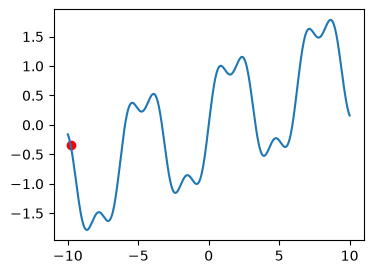

In [30]:
plt.figure(figsize=(4,3)) 
plt.plot(x, fx)
plt.scatter(localmin, f(localmin), c='red')
plt.show() 

In [65]:
localmins = np.zeros((5, training_epoch)) 
localmins.shape

(5, 100)

### grad = derv(localmin ) : 

مثلاً در \(x=-3\):
###    اگر شیب خط منفی باشد اگر به سمت چپ بریم مقدار کمتر میشود پس باید به سمت راست حرکت کنیم چون که باید مشتق برابر با 0 شود مقادیر 0 برای مینیموم هست 


###    اگر هم که شیب مثبت باشد باید به سمت چپ حرکت کنیم که کمتر شود و به 0 نزدیک تر شویم 

In [72]:

# Parameters 

lr = .01 
training_epoch = 100

In [74]:
for i in localmins : 

    # random starting point 
    localmin = np.random.choice(x, 1) 

    for f in range(training_epoch) : 
        
        grad = df(localmin) 
        
        # 
        localmin -= lr * grad 
        i[f] = localmin[0]
        


In [76]:
localmins

array([[-3.43959566, -3.42539979, -3.4108696 , -3.39601035, -3.38082893,
        -3.36533391, -3.34953561, -3.33344621, -3.3170797 , -3.30045197,
        -3.28358075, -3.26648562, -3.24918788, -3.23171051, -3.214078  ,
        -3.19631622, -3.1784522 , -3.16051396, -3.14253024, -3.12453028,
        -3.10654353, -3.08859938, -3.07072691, -3.05295463, -3.03531022,
        -3.01782027, -3.00051011, -2.98340363, -2.96652307, -2.94988896,
        -2.93351996, -2.91743287, -2.90164254, -2.8861619 , -2.87100197,
        -2.85617192, -2.84167909, -2.82752916, -2.81372614, -2.80027256,
        -2.78716953, -2.77441691, -2.76201335, -2.74995647, -2.73824297,
        -2.72686869, -2.71582879, -2.70511777, -2.69472965, -2.68465796,
        -2.67489591, -2.66543641, -2.65627215, -2.64739565, -2.63879934,
        -2.63047555, -2.62241664, -2.61461495, -2.60706287, -2.59975287,
        -2.59267752, -2.58582949, -2.5792016 , -2.5727868 , -2.56657821,
        -2.56056909, -2.55475289, -2.54912322, -2.5